In [4]:
#Step 1. Imports + Setup
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

# Load SAM model
sam_checkpoint = "Checkpoints/sam_vit_b_01ec64.pth"   # <-- adjust if needed
model_type = "vit_b"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to("cuda")   # use GPU


Sam(
  (image_encoder): ImageEncoderViT(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=768, out_features=2304, bias=True)
          (proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): Linear(in_features=3072, out_features=768, bias=True)
          (act): GELU(approximate='none')
        )
      )
    )
    (neck): Sequential(
      (0): Conv2d(768, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): LayerNorm2d()
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (3): LayerNorm2d()
    )


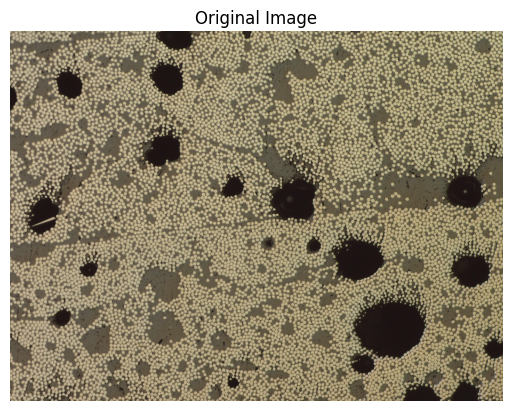

In [2]:
# Step 2. Load Image
image_path =  "images/20250722_141557.jpg"   # <-- change this
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()


In [11]:
# Step 3. Automatic Mask Generation
mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=64,        # higher = more masks
    pred_iou_thresh=0.88,      # quality threshold
    stability_score_thresh=0.95,
    min_mask_region_area=10,  # filter out tiny masks
)

masks = mask_generator.generate(image)
print("Number of masks generated:", len(masks))


Number of masks generated: 138


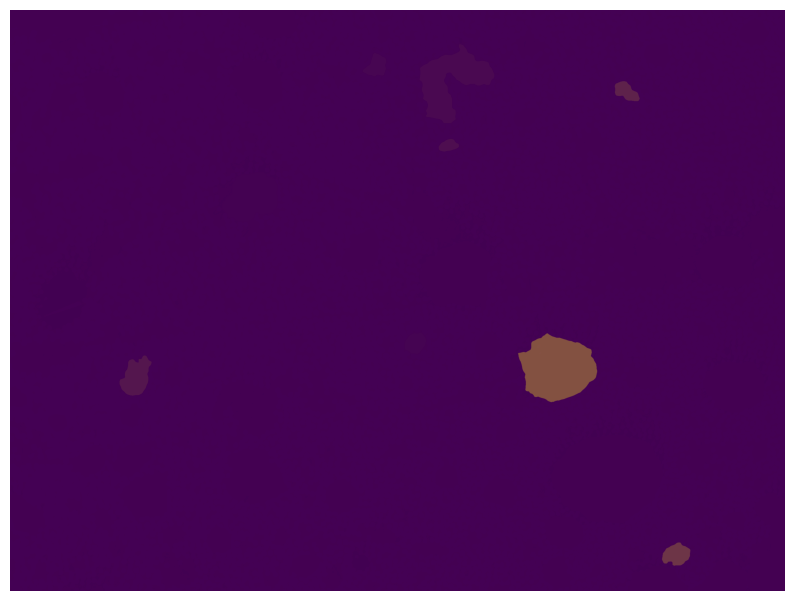

In [12]:
# Step 4. Visualize All Masks (overlay)
def show_masks(image, masks, limit=50):
    plt.figure(figsize=(10,10))
    plt.imshow(image)
    for i, m in enumerate(masks[:limit]):
        seg = m["segmentation"]
        plt.imshow(seg, alpha=0.35)   # overlay
    plt.axis("off")
    plt.show()

show_masks(image, masks, limit=50)  # show first 50


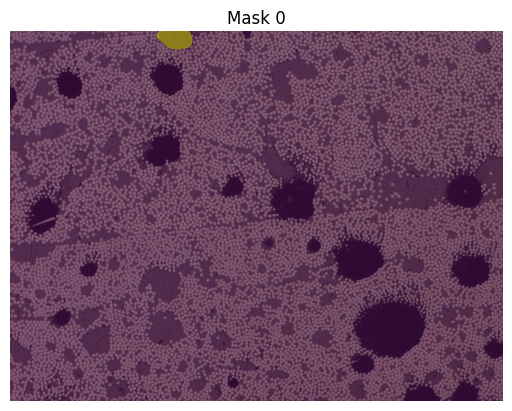

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_0.png


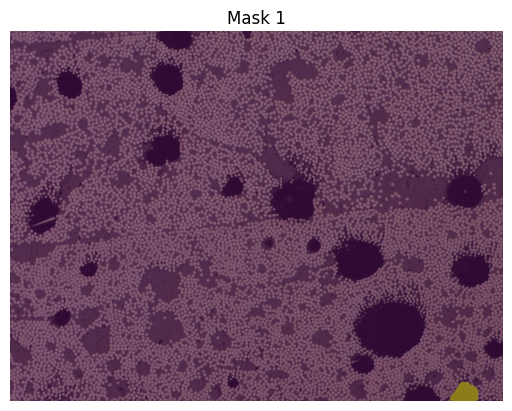

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_1.png


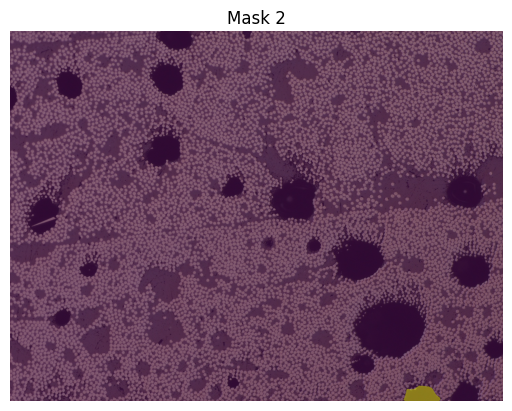

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_2.png


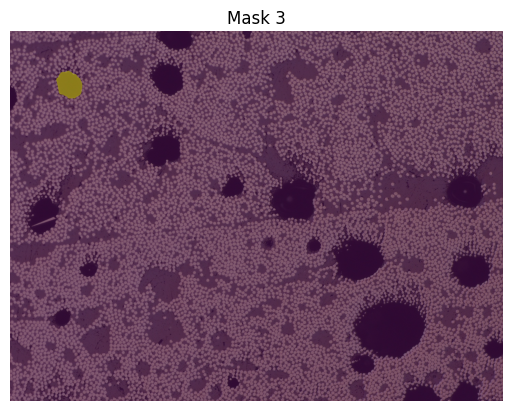

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_3.png


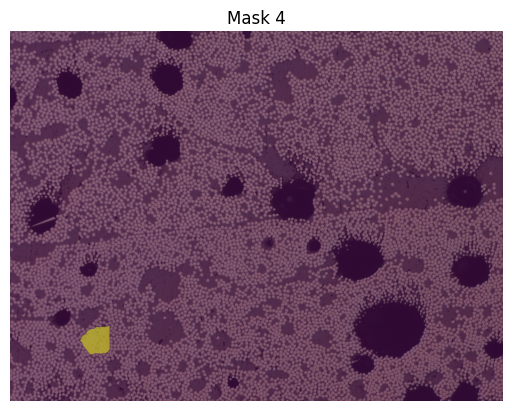

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_4.png


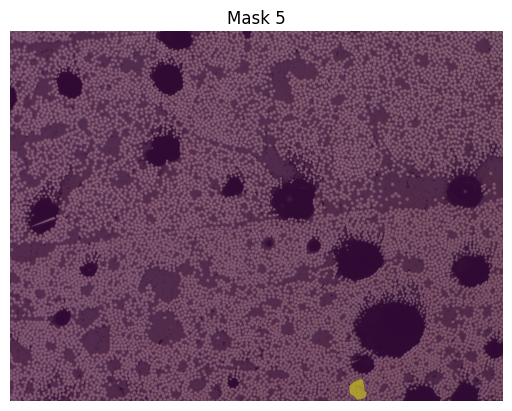

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_5.png


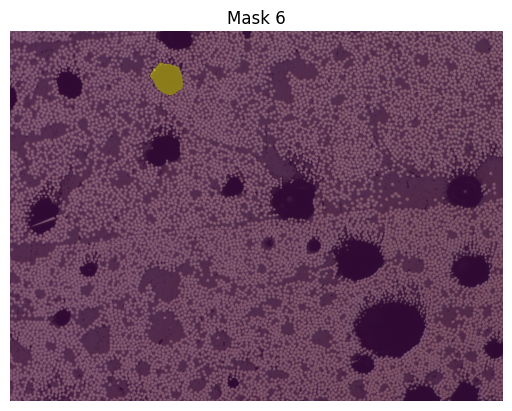

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_6.png


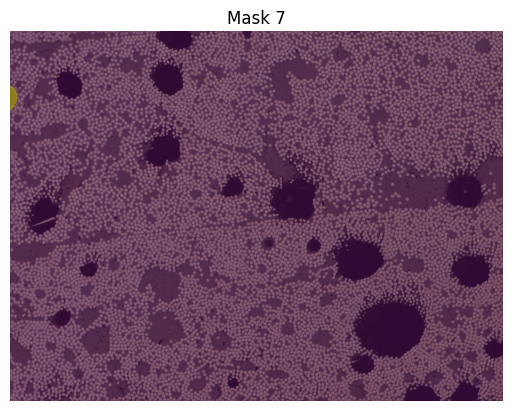

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_7.png


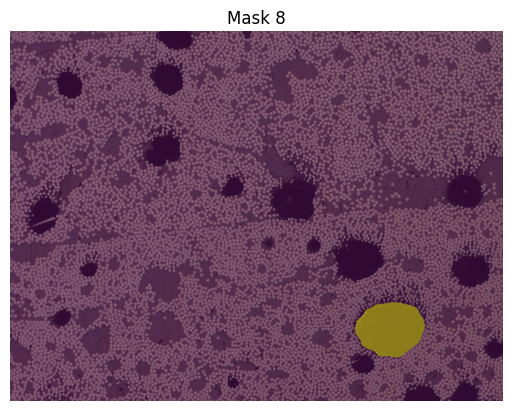

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_8.png


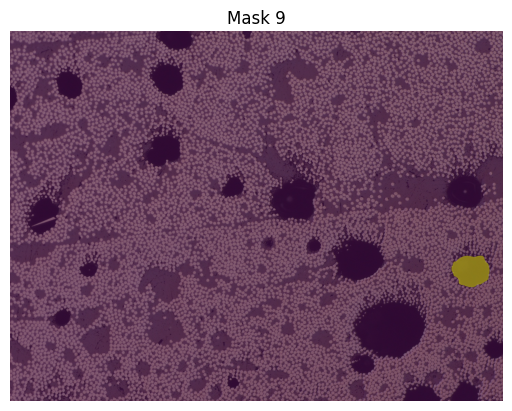

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_9.png


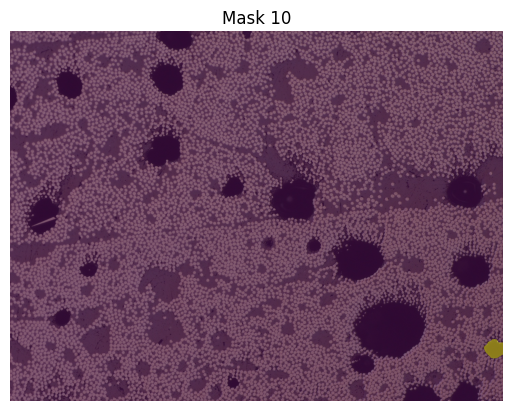

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_10.png


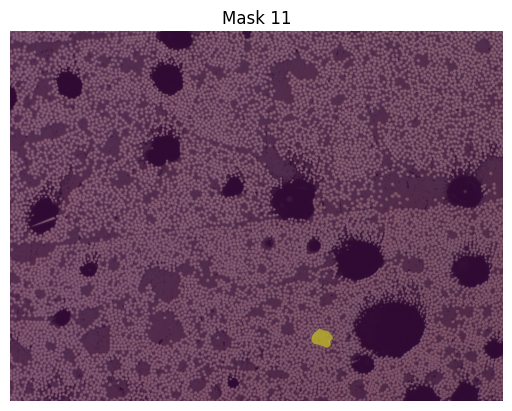

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_11.png


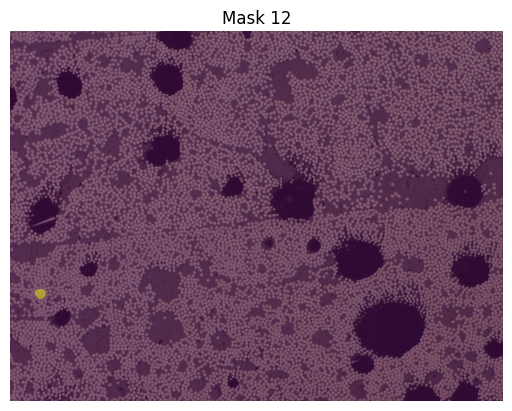

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_12.png


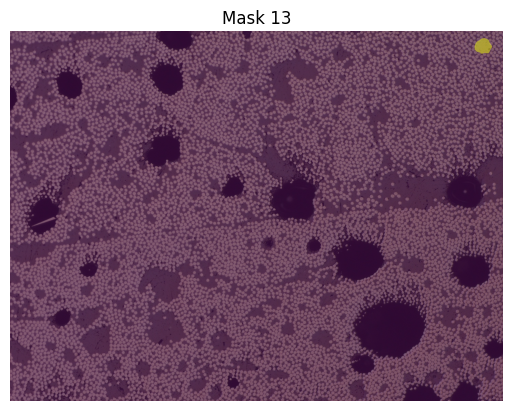

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_13.png


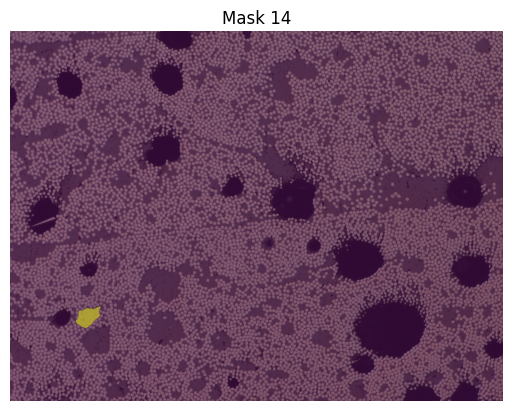

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_14.png


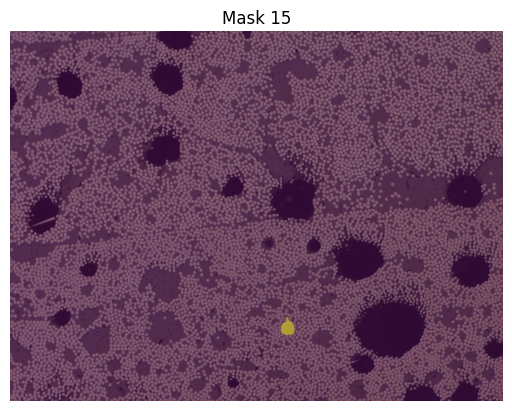

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_15.png


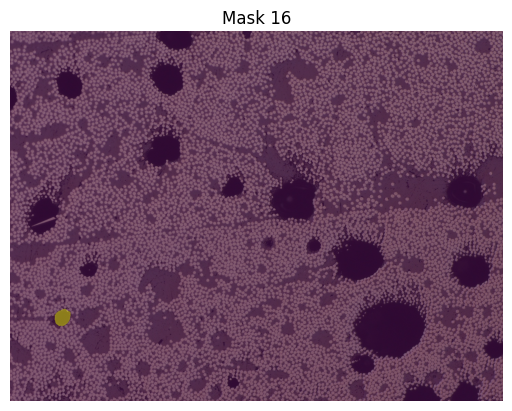

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_16.png


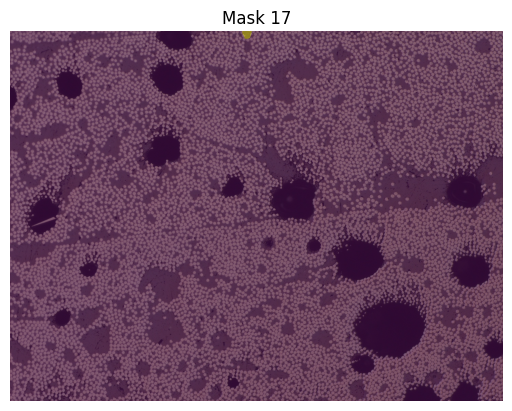

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_17.png


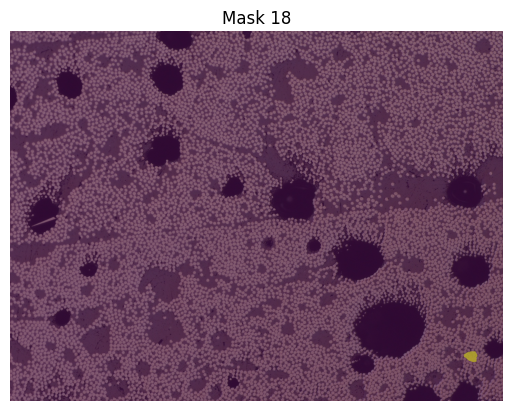

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_18.png


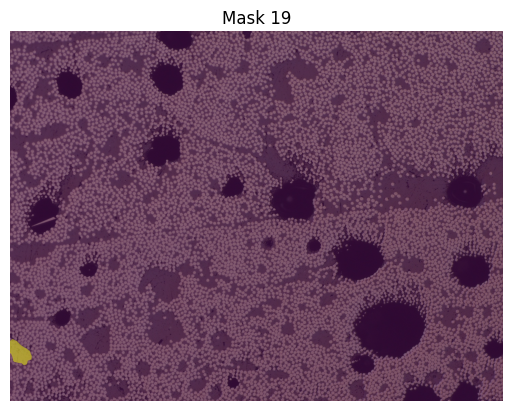

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_19.png


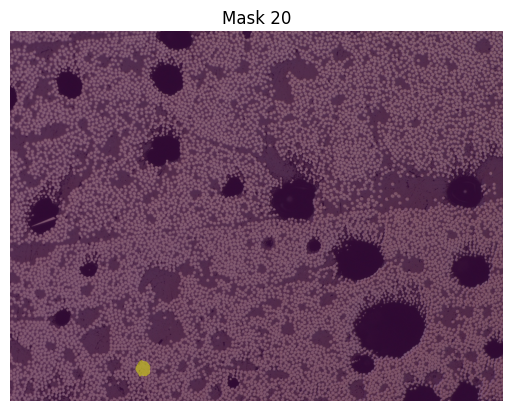

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_20.png


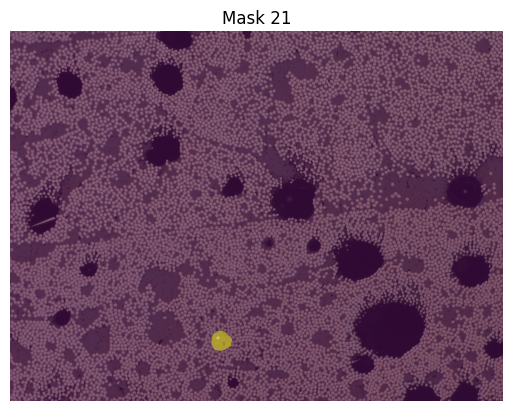

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_21.png


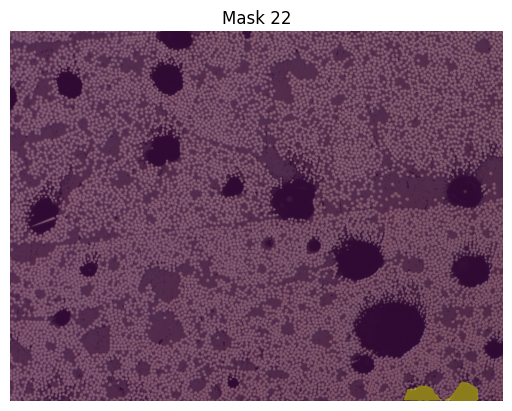

Class? (1/2/3 or ENTER to skip):  


⏭ Skipped


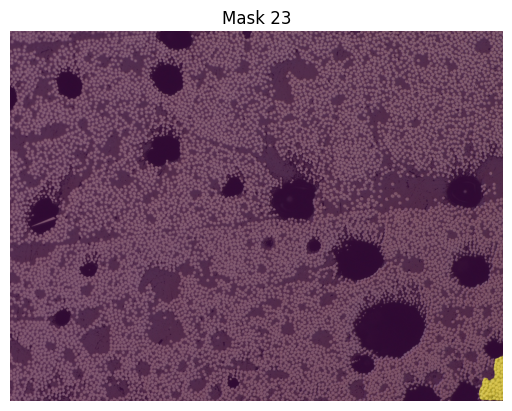

Class? (1/2/3 or ENTER to skip):  


⏭ Skipped


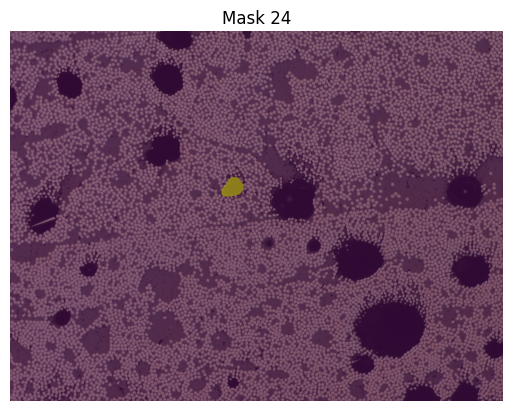

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_24.png


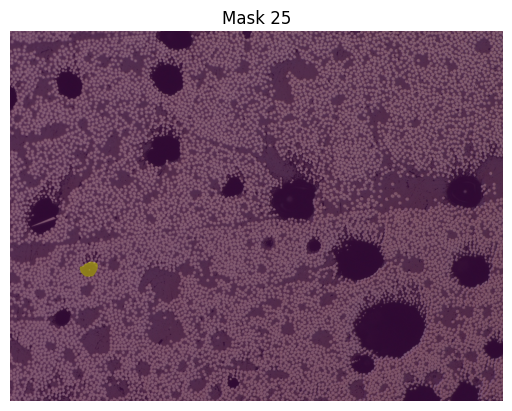

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_25.png


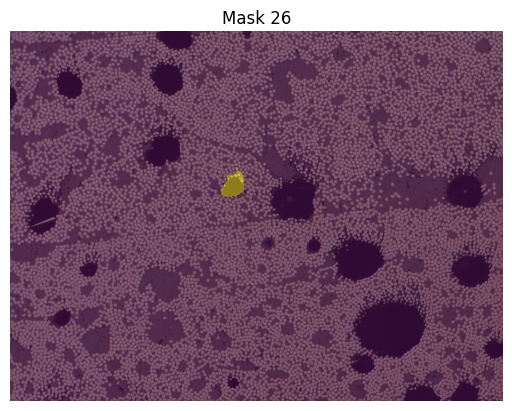

Class? (1/2/3 or ENTER to skip):  


⏭ Skipped


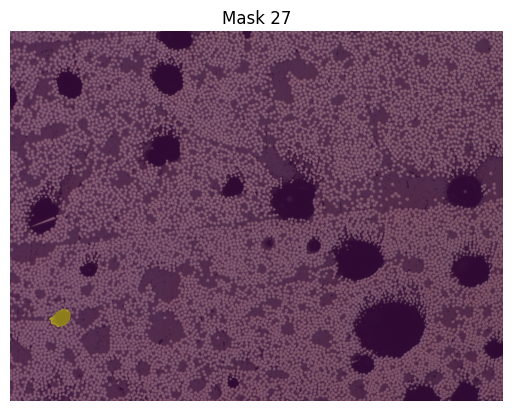

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_27.png


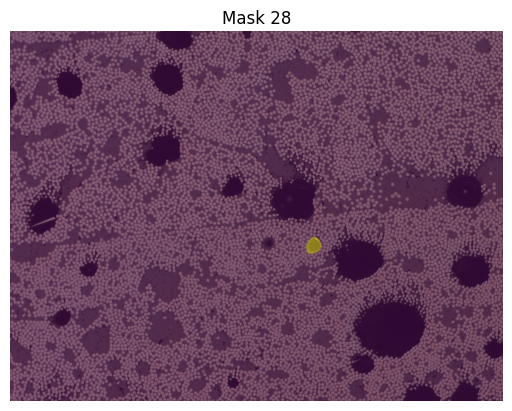

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_28.png


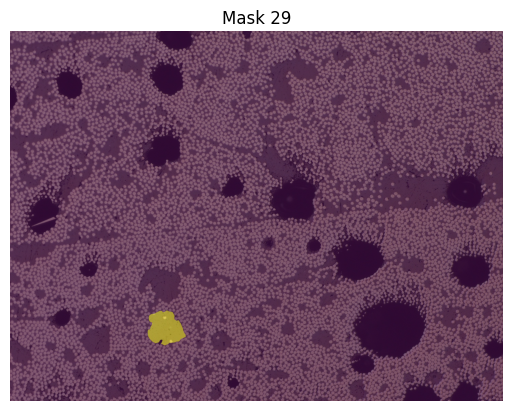

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_29.png


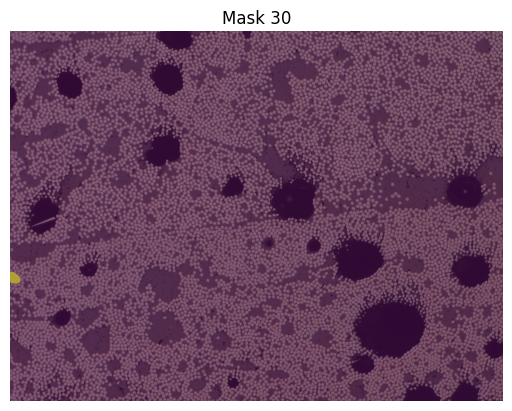

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_30.png


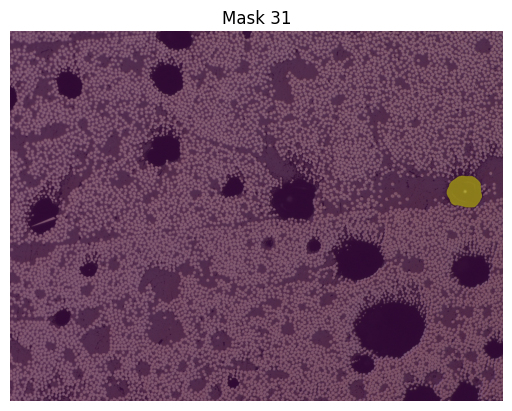

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_31.png


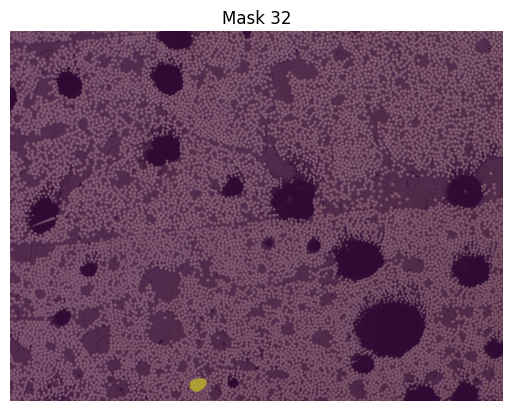

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_32.png


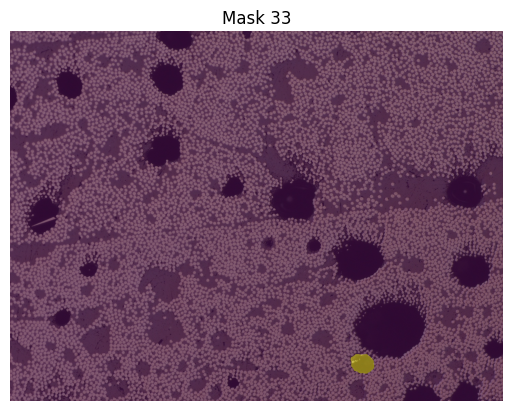

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_33.png


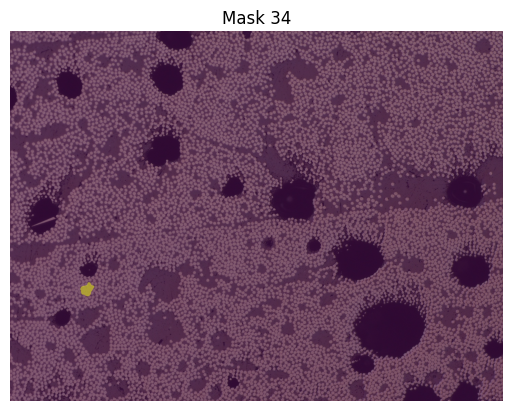

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_34.png


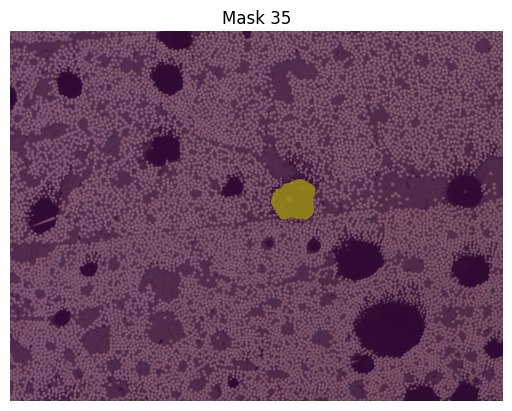

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_35.png


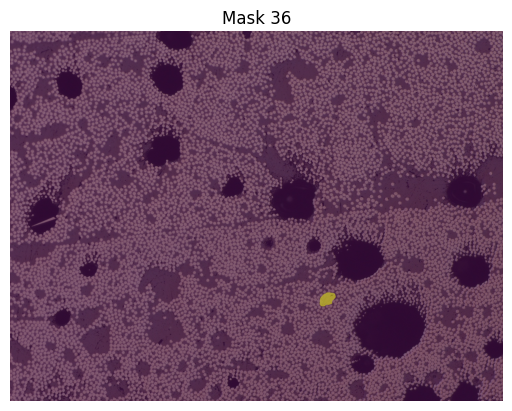

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_36.png


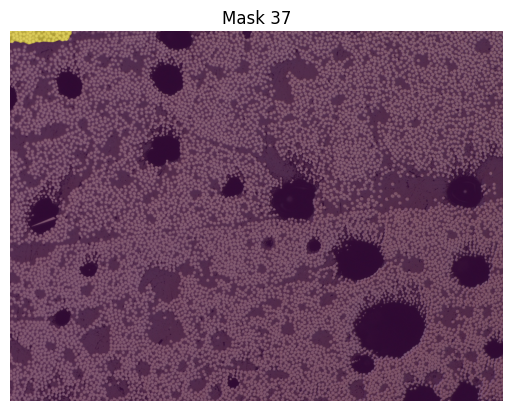

Class? (1/2/3 or ENTER to skip):  


⏭ Skipped


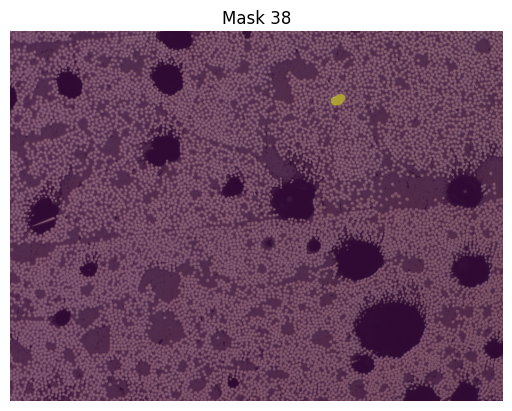

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_38.png


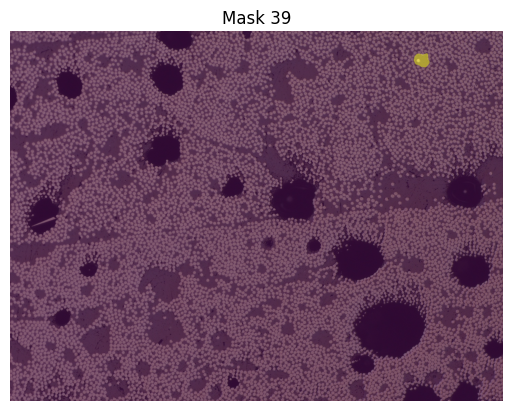

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_39.png


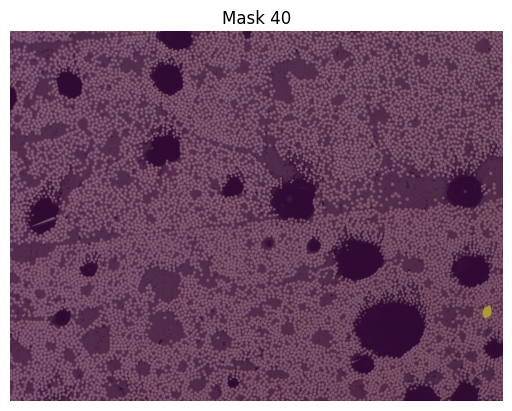

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_40.png


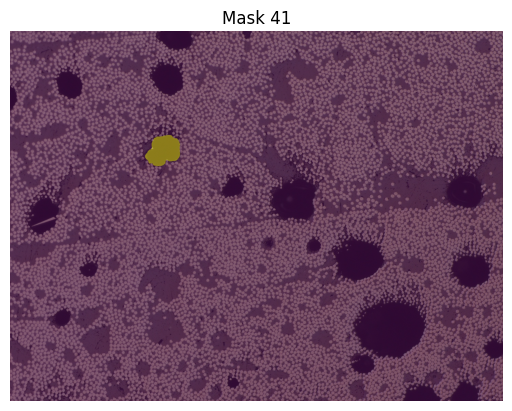

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_41.png


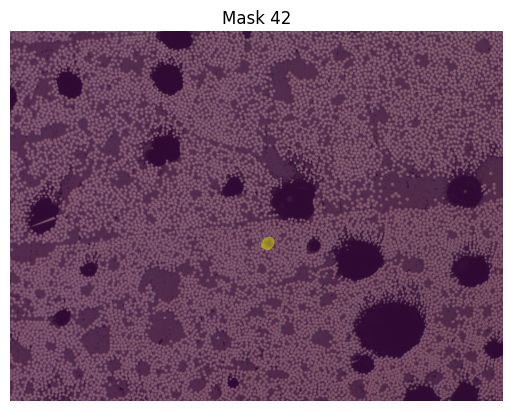

Class? (1/2/3 or ENTER to skip):  


⏭ Skipped


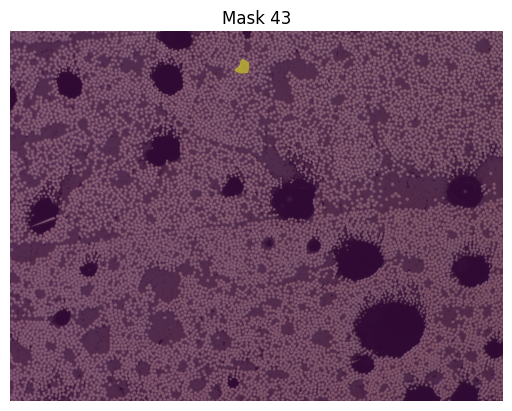

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_43.png


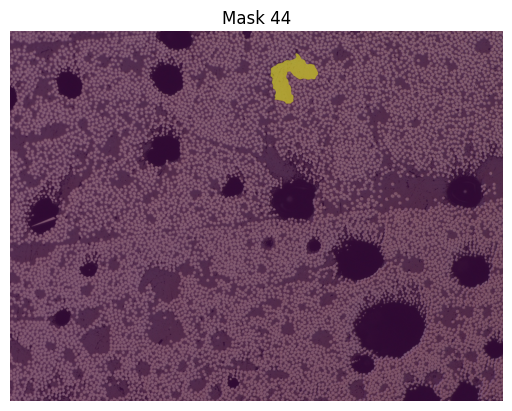

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_44.png


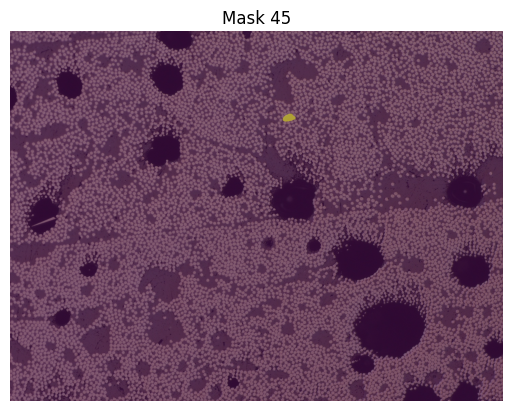

Class? (1/2/3 or ENTER to skip):  


⏭ Skipped


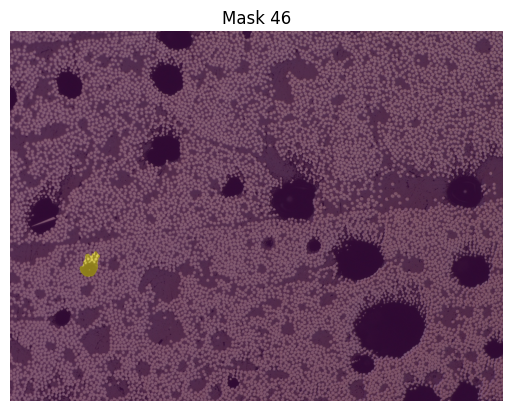

Class? (1/2/3 or ENTER to skip):  


⏭ Skipped


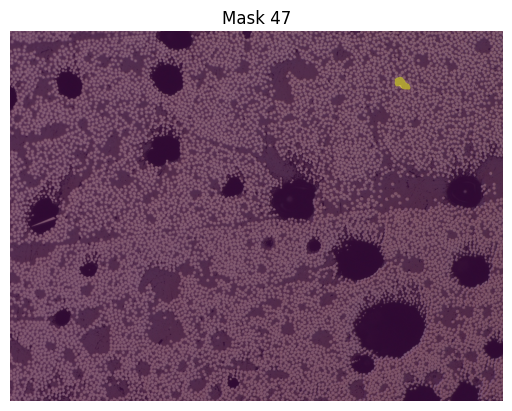

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_47.png


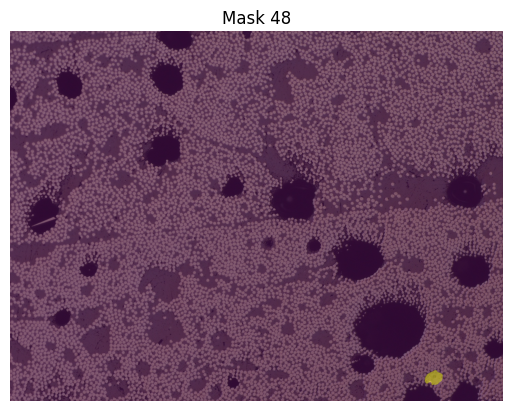

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_48.png


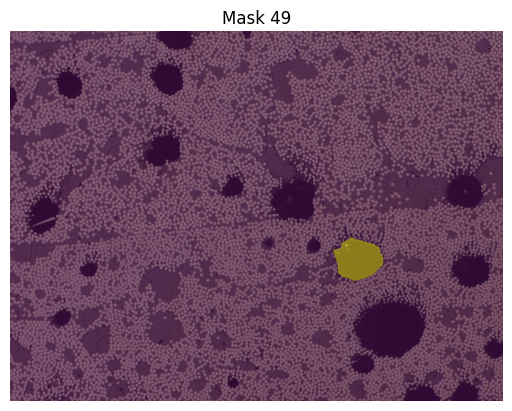

Class? (1/2/3 or ENTER to skip):  3


✅ Saved to Masks/Class3/mask_49.png


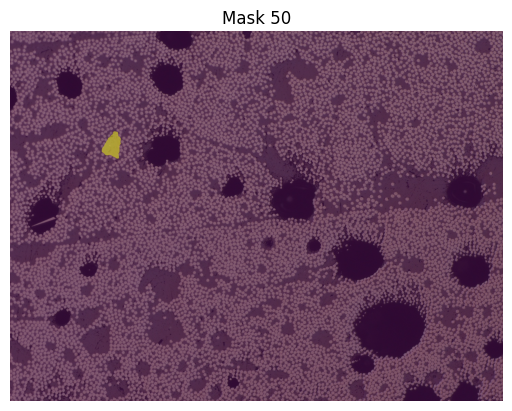

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_50.png


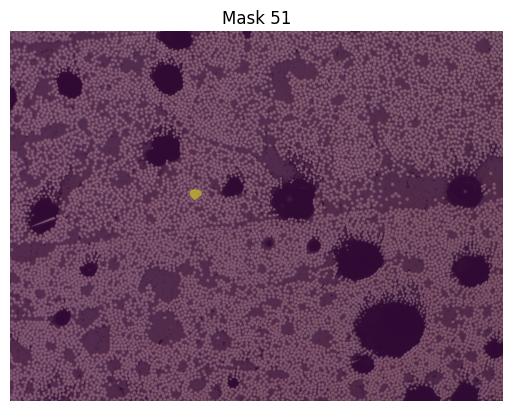

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_51.png


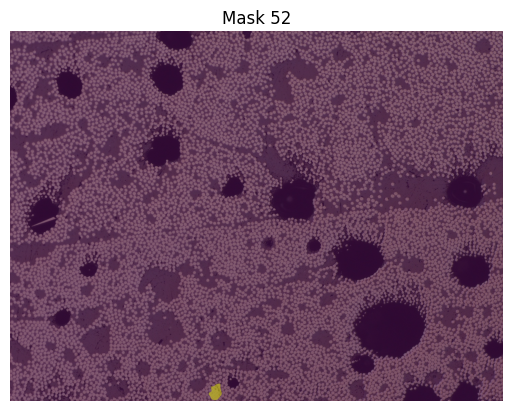

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_52.png


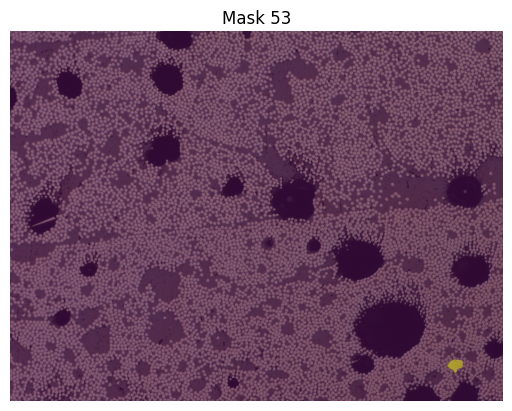

Class? (1/2/3 or ENTER to skip):  1


✅ Saved to Masks/Class1/mask_53.png


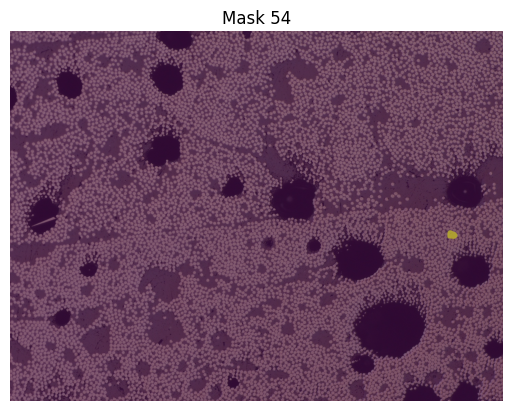

In [ ]:
# Step 5. Interactive Mask Selection (assign classes)
# We’ll make a simple function: click a mask ID, assign it to class 1, 2, or 3.

# Prepare folders for saving
os.makedirs("Masks/Class1", exist_ok=True)
os.makedirs("Masks/Class2", exist_ok=True)
os.makedirs("Masks/Class3", exist_ok=True)

# Function to save mask
def save_mask(mask, save_path):
    mask_img = (mask.astype(np.uint8) * 255)
    cv2.imwrite(save_path, mask_img)

# Iterate masks manually (simplified)
for idx, m in enumerate(masks[:200]):   # limit to first 200 for now
    plt.imshow(image)
    plt.imshow(m["segmentation"], alpha=0.5)
    plt.title(f"Mask {idx}")
    plt.axis("off")
    plt.show()

    cls = input("Class? (1/2/3 or ENTER to skip): ")
    if cls in ["1", "2", "3"]:
        save_path = f"Masks/Class{cls}/mask_{idx}.png"
        save_mask(m["segmentation"], save_path)
        print(f"✅ Saved to {save_path}")
    else:
        print("⏭ Skipped")
